***Week 9 Jupyter Notebook — Assignment Instructions***

Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone Two, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions.

For this week, include ideas such as gradient boost, learning rate, number of estimators, tree depth, and regularization. This homework should be submitted for peer review in **9.3 Peer Review: Week 9 Jupyter Notebook**. Complete and submit your Jupyter Notebook homework by 11:59pm ET on Sunday.

In Week 12, compile findings from the weekly notebooks into Milestone Two. The referenced rubric/link was not provided; this notebook addresses the supplied weekly instructions. The saved notebook is prepared for local review; submission is a separate course-system action.

# Week 9: Gradient boosting and regularization

Calvin Baker · DX799 Integrated Capstone · Three independent dataset analyses

## tl;dr

- **Loan_Default.csv** — recorded Status 1: **Gradient boost**, test AUC **0.647**, AP **0.398**, F1 at the validation cutoff **0.409**, test n=2,400.
- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Gradient boost**, test AUC **0.635**, AP **0.217**, F1 at the validation cutoff **0.281**, test n=2,400.
- **bank_customers.csv** — checking account versus savings/CD: **Gradient boost**, test AUC **0.333**, AP **0.758**, F1 at the validation cutoff **0.444**, test n=8.

Gradient boosting improved Loan_Default ranking descriptively and was close to logistic regression on LendingClub. Stage-wise loss curves show why more trees and deeper fits can overfit. The bank study uses only 39 eligible rows and is a methods demonstration.

**Delivered run:** 34 code cells executed from a fresh kernel with 21 saved figures. These static summaries describe the saved run; revise them after changing inputs or settings.

## Context & Methods

**Question:** Can sequentially fitted trees improve the conservative classification tasks while controlling model complexity?

Gradient boosting adds trees to a raw score: $F_m(x)=F_{m-1}(x)+\eta h_m(x)$. With binary log loss, the next tree learns from negative gradients related to $y-p$; trees are added sequentially rather than independently averaged as in a random forest. A logistic transformation converts the accumulated score into a class probability.

**Learning rate** $\eta$ shrinks each update; **number of estimators** determines the number of stages. They interact: a small rate can underfit with too few stages. **Maximum depth** limits within-tree interactions. **Minimum leaf size**, **subsampling**, shrinkage and a finite tree count constrain fitting. Subsampling below 1 fits each stage on a random subset of training rows. This study uses explicit tree counts and no automatic early stopping, preserving grouped bank validation.

### Key Assumptions and evaluation plan

- Each CSV is an independent source; there are no joins between unrelated people or loans. The source paths are `DATA/Loan_Default.csv`, `DATA/accepted_2007_to_2018Q4.csv`, and `DATA/bank_customers.csv`.
- Continue Week 4's classification targets and conservative predictor sets. For matched weekly experiments, take **12,000 uniformly sampled rows** per loan dataset (or all rows if fewer). Weeks 8 and 9 use the same loading, sampling and split code as Weeks 5–6. This differs from Week 4's full Loan_Default population and 24,000-row LendingClub sample; do **not** attribute cross-week score changes solely to algorithms.
- Loans use a seed-42, stratified 60% train / 20% validation / 20% test split. Bank records use Week 4's account-group split and three-fold group CV. No account crosses partitions or CV folds. Loan IDs identify rows, not verified unique borrowers; random splits assume sufficient row independence.
- Training-only three-fold CV chooses parameters by mean **ROC AUC**. There is one prespecified boosting family; validation does not choose another family. AP and fold variation are shown for context. In a tie, the first listed family wins. Finite grids may select an edge; search ranges would need expansion inside training for further optimization.
- Select the F1 cutoff only on validation. Freeze the training-fitted model and cutoff, then evaluate on test once. **No development-set refit** is performed, preserving the score scale used for threshold selection. Prespecified models and fixed-C logistic baselines are also shown on test, without choosing another winner afterward.
- Accuracy alone is misleading with imbalance. Report AUC, AP, prevalence, precision, recall, F1, balanced accuracy, predicted-positive counts and exact confusion counts. A prior-probability/majority baseline has AUC 0.5 and AP equal to prevalence. AUC measures ranking; a high AUC does not guarantee useful decisions or calibrated probabilities.
- The bank reference date remains **2026-09-26** for comparability with prior weeks; it is not today's date. It yields 39 eligible records. Exclusion reasons can overlap. Bank estimates demonstrate methods and are too small for reliable population conclusions.
- Original CSVs stay unchanged. Use the repository's `requirements-notebooks.txt`, then **Restart Kernel → Run All**. Each notebook is self-contained and prints the environment versions; no hidden fitted artifacts are required.

### 1. Set up the environment

Use `requirements-notebooks.txt`; run from the repository or its parent workspace. Seeds and bounded numerical threads make the workflow reproducible.

In [1]:
from pathlib import Path
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

# A fixed seed and bounded numerical threads make the workflow repeatable.
SEED = 42
thread_limit = threadpool_limits(limits=1)
warnings.filterwarnings('error', category=ConvergenceWarning)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 115,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'axes.axisbelow': True})
BLUE, ORANGE, GRAY = '#245E91', '#B96520', '#50545A'

# Support opening from the repository itself or its parent workspace.
data_candidates = [Path.cwd() / 'DATA',
                   Path.cwd() / 'Data-Science-Capstone-DX799' / 'DATA']
DATA_DIR = next((p for p in data_candidates if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Open this notebook from the repository or its parent; DATA is required.')
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'NumPy': np.__version__, 'scikit-learn': sklearn.__version__,
                   'SciPy': scipy.__version__, 'seed': SEED}, name='Execution environment'))
from sklearn.model_selection import StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
import time
SAMPLE_SIZE = 12_000
results = []
from sklearn.metrics import log_loss, brier_score_loss

Python          3.13.5
pandas           3.0.0
NumPy            2.4.1
scikit-learn     1.8.0
SciPy           1.17.0
seed                42
Name: Execution environment, dtype: object

### 2. Define shared, unfitted tools

All preprocessing is refitted inside each training fold. Each dataset has independent fitted models.

In [2]:
def extra_split(X, y, groups=None, classification=False):
    """Use a row split for loans and account-group separation for bank records."""
    if groups is None:
        development, test = train_test_split(np.arange(len(X)), test_size=0.20,
            random_state=SEED, stratify=y if classification else None)
        train, valid = train_test_split(development, test_size=0.25, random_state=SEED,
            stratify=y.iloc[development] if classification else None)
        cv = (StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
              if classification else KFold(n_splits=3, shuffle=True, random_state=SEED))
        folds = list(cv.split(X.iloc[train], y.iloc[train]))
    else:
        development, test = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
            random_state=SEED).split(X, y, groups))
        train_local, valid_local = next(GroupShuffleSplit(n_splits=1, test_size=0.25,
            random_state=SEED).split(X.iloc[development], y.iloc[development], groups.iloc[development]))
        train, valid = development[train_local], development[valid_local]
        # Do not split records from the same account across CV folds either.
        folds = list(GroupKFold(n_splits=3).split(X.iloc[train], y.iloc[train], groups.iloc[train]))
        sets = [set(groups.iloc[index]) for index in [train, valid, test]]
        assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
    assert len(set(train) | set(valid) | set(test)) == len(X)
    if classification:
        for index in [train, valid, test]:
            assert y.iloc[index].nunique() == 2, 'Both classes are required in every evaluation split.'
        for fit, holdout in folds:
            assert y.iloc[train].iloc[fit].nunique() == 2
            assert y.iloc[train].iloc[holdout].nunique() == 2
    return train, valid, test, development, folds


def prepare(numeric, categorical, scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    transformers = [('numeric', Pipeline(steps), numeric)]
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

def pipeline(model, scale=True):
    return Pipeline([('prepare', prepare(numeric, categorical, scale)), ('model', model)])

def score_values(model, data):
    return model.predict_proba(data)[:, 1]

def metrics(actual, scores, prediction):
    return {'ROC AUC': roc_auc_score(actual, scores),
            'Average precision': average_precision_score(actual, scores),
            'Accuracy': accuracy_score(actual, prediction),
            'Balanced accuracy': balanced_accuracy_score(actual, prediction),
            'Precision': precision_score(actual, prediction, zero_division=0),
            'Recall': recall_score(actual, prediction, zero_division=0),
            'F1': f1_score(actual, prediction, zero_division=0),
            'Predicted positive': int(np.sum(prediction))}

def tune(model, grid, scale=True):
    search = GridSearchCV(pipeline(model, scale), grid, cv=folds,
        scoring={'auc':'roc_auc','ap':'average_precision'}, refit='auc',
        n_jobs=1, return_train_score=True, error_score='raise')
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    estimator = search.best_estimator_
    row = {'CV AUC': search.best_score_,
           'CV AUC SD': search.cv_results_['std_test_auc'][search.best_index_],
           'Train AUC': roc_auc_score(y_train, score_values(estimator, X_train)),
           'Validation AUC': roc_auc_score(y_valid, score_values(estimator, X_valid)),
           'Validation AP': average_precision_score(y_valid, score_values(estimator, X_valid)),
           'Fit seconds': elapsed, 'Parameters': search.best_params_}
    return search, row

## Data and Results

## A. Loan_Default.csv — independent analysis

**Outcome:** recorded `Status=1` versus 0, with all valid statuses eligible before uniform sampling. Use loan amount, income, credit score, term, loan type, purpose and occupancy. Exclude identifiers, sensitive demographic fields, pricing, property/LTV/DTI fields and credit_type because the prior leakage audit found status-linked artifacts. Missingness in included fields can still carry collection artifacts; removing the worst fields does not prove leakage-free future prediction. The observation window/status semantics are not documented in the supplied files.

### A1. Load and reconcile source data

In [3]:
dataset_name = 'Loan_Default.csv'
outcome_label = 'recorded Status 1'
source_frame = pd.read_csv(DATA_DIR / dataset_name)
assert source_frame['ID'].notna().all() and source_frame['ID'].is_unique
assert source_frame['Status'].notna().all() and set(source_frame['Status'].unique()) == {0,1}
assert not source_frame.duplicated().any()
# Uniform sampling is independent of outcome. Preserve original indices for audits.
frame = source_frame.sample(n=min(SAMPLE_SIZE, len(source_frame)), random_state=SEED).copy()
numeric = ['loan_amount', 'income', 'Credit_Score', 'term']
categorical = ['loan_type', 'loan_purpose', 'occupancy_type']
X = frame[numeric + categorical].copy()
for name in categorical:
    X[name] = X[name].astype(object).where(X[name].notna(), np.nan)
y = frame['Status'].astype(int)
groups = None
display(pd.Series({'source rows':len(source_frame), 'valid target rows':len(source_frame),
    'uniform modeling sample':len(frame), 'not sampled':len(source_frame)-len(frame)}, name='Source reconciliation'))

source rows                148670
valid target rows          148670
uniform modeling sample     12000
not sampled                136670
Name: Source reconciliation, dtype: int64

### A2. Reserve evaluation records and audit training inputs

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,5497,1703,0.2365,7200
Validation,2400,1832,568,0.2367,2400
Test,2400,1832,568,0.2367,2400


,Training missing (%)
loan_amount,0.0000
income,6.6667
Credit_Score,0.0000
term,0.0000
loan_type,0.0000
loan_purpose,0.0833
occupancy_type,0.0000


,loan_amount,income,Credit_Score,term
min,"36,500.0000",0.0000,500.0000,96.0000
median,"306,500.0000","5,820.0000",700.0000,360.0000
max,"3,006,500.0000","146,520.0000",900.0000,360.0000


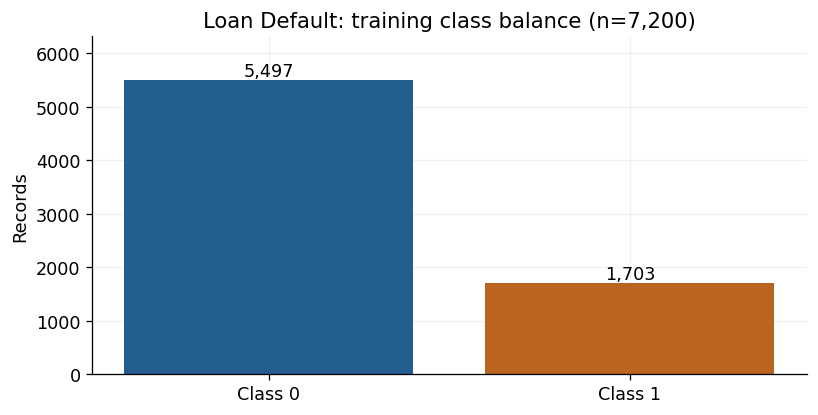

In [4]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### Audit status-linked missingness

The following training-only check demonstrates why seemingly predictive fields are excluded. It is not a candidate model.

In [5]:
audit_fields=['rate_of_interest','Interest_rate_spread','Upfront_charges','property_value','LTV','dtir1']
training_source=source_frame.loc[X_train.index]
audit=training_source.groupby('Status')[audit_fields].agg(lambda s:s.isna().mean()).T
audit.columns=['Missing share, class 0','Missing share, class 1']
display(audit)
artifact_accuracy=accuracy_score(y_train,training_source['rate_of_interest'].isna().astype(int))
display(Markdown(f'**Training-only audit:** the missing-interest-rate rule has {artifact_accuracy:.2%} accuracy. '
    'Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. '
    'This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.'))

,"Missing share, class 0","Missing share, class 1"
rate_of_interest,0.0000,0.9941
Interest_rate_spread,0.0000,1.0000
Upfront_charges,0.0331,0.9953
property_value,0.0000,0.4116
LTV,0.0000,0.4116
dtir1,0.0773,0.4422


**Training-only audit:** the missing-interest-rate rule has 99.86% accuracy. Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.

### A3. Tune parameters inside training CV

In [6]:
# Two paired regularization profiles keep the search bounded.
# Profile effects are joint: leaf size and subsampling cannot be attributed separately here.
leaf_sizes=[1,3] if groups is not None else [10,30]
grid=[{'model__learning_rate':[0.03,0.1],'model__n_estimators':[60,160],
    'model__max_depth':[1,3],'model__min_samples_leaf':[leaf], 'model__subsample':[subsample]}
    for leaf,subsample in zip(leaf_sizes,[1.0,0.7])]
search,row=tune(GradientBoostingClassifier(loss='log_loss',random_state=SEED),grid,scale=False)
searches={'Gradient boost':search}; fitted={'Gradient boost':search.best_estimator_}
comparison=pd.DataFrame([{'Model':'Gradient boost',**row}]).set_index('Model')
chosen_name='Gradient boost'; selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Parameter':k.removeprefix('model__'),'Value':v} for k,v in search.best_params_.items()]))
display(Markdown('Three-fold training CV selects all boosting parameters. Validation is reserved for diagnostics and the F1 cutoff; '
    'the stage plots below do not change the selected model or number of trees. No automatic early stopping is used.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Gradient boost,0.6372,0.0068,0.6915,0.6439,0.4163,9.4394


,Parameter,Value
0,learning_rate,0.0300
1,max_depth,3.0000
2,min_samples_leaf,30.0000
3,n_estimators,160.0000
4,subsample,0.7000


Three-fold training CV selects all boosting parameters. Validation is reserved for diagnostics and the F1 cutoff; the stage plots below do not change the selected model or number of trees. No automatic early stopping is used.

### A4. Inspect learning rate, tree count and depth

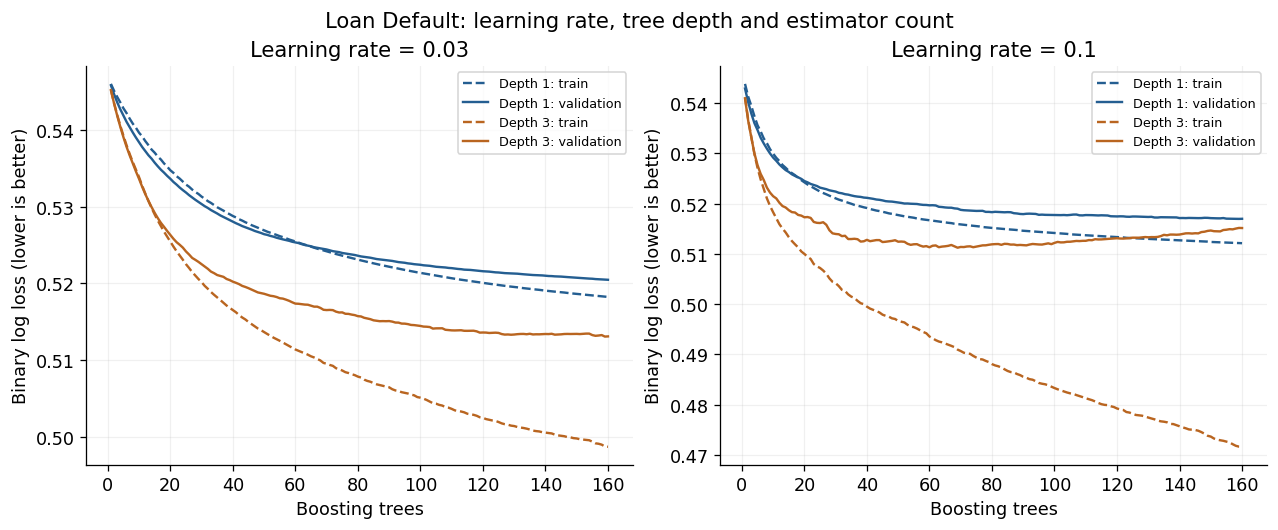

,Learning rate,Depth,Trees,Train log loss,Validation log loss
0,0.0300,1,60,0.5255,0.5254
1,0.0300,1,160,0.5182,0.5205
2,0.0300,3,60,0.5114,0.5174
3,0.0300,3,160,0.4987,0.5131
4,0.1000,1,60,0.5167,0.5197
5,0.1000,1,160,0.5121,0.5170
6,0.1000,3,60,0.4936,0.5113
7,0.1000,3,160,0.4716,0.5151


In [7]:
# Prespecified paths: training-fitted preprocessing; validation is diagnostic only.
path_prepare=prepare(numeric,categorical,scale=False)
Z_train=path_prepare.fit_transform(X_train); Z_valid=path_prepare.transform(X_valid)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
path_rows=[]
for ax,rate in zip(axes,[0.03,0.1]):
    for depth,color in [(1,BLUE),(3,ORANGE)]:
        path=GradientBoostingClassifier(learning_rate=rate,n_estimators=160,max_depth=depth,
            min_samples_leaf=leaf_sizes[0],subsample=1.0,random_state=SEED).fit(Z_train,y_train)
        train_loss=[log_loss(y_train,p,labels=[0,1]) for p in path.staged_predict_proba(Z_train)]
        valid_loss=[log_loss(y_valid,p,labels=[0,1]) for p in path.staged_predict_proba(Z_valid)]
        stages=np.arange(1,161)
        ax.plot(stages,train_loss,color=color,linestyle='--',label=f'Depth {depth}: train')
        ax.plot(stages,valid_loss,color=color,linestyle='-',label=f'Depth {depth}: validation')
        for stage in [60,160]:
            path_rows.append({'Learning rate':rate,'Depth':depth,'Trees':stage,
                'Train log loss':train_loss[stage-1],'Validation log loss':valid_loss[stage-1]})
    ax.set(title=f'Learning rate = {rate}',xlabel='Boosting trees',ylabel='Binary log loss (lower is better)')
    ax.legend(fontsize=8)
fig.suptitle(f'{plot_label}: learning rate, tree depth and estimator count')
plt.show()
display(pd.DataFrame(path_rows))

### A5. Inspect regularization in training CV

Mean training-fold AUC  \
param_model__max_depth Profile                                       
1                      70% rows; leaf ≥30                   0.6434   
                       Full rows; leaf ≥10                  0.6396   
3                      70% rows; leaf ≥30                   0.7133   
                       Full rows; leaf ≥10                  0.7131   

                                            Mean held-out-fold AUC  
param_model__max_depth Profile                                      
1                      70% rows; leaf ≥30                   0.6209  
                       Full rows; leaf ≥10                  0.6187  
3                      70% rows; leaf ≥30                   0.6341  
                       Full rows; leaf ≥10                  0.6328

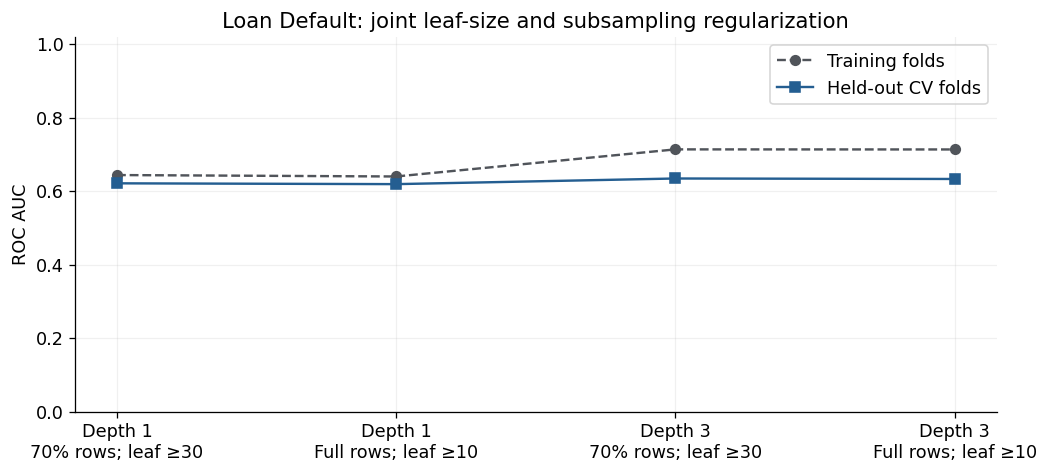

Values average equally over the four learning-rate/tree-count settings per depth/profile. Subsampling and larger leaves are changed together; this comparison does not isolate their individual effects. Shrinkage, depth limits and a finite tree count are additional regularizers.

In [8]:
cv=pd.DataFrame(search.cv_results_)
cv['Profile']=np.where(cv['param_model__subsample'].astype(float)==1.0,
    f'Full rows; leaf ≥{leaf_sizes[0]}',f'70% rows; leaf ≥{leaf_sizes[1]}')
# Average over the same rate/tree-count combinations within each depth/profile.
reg=cv.groupby(['param_model__max_depth','Profile'],sort=True)[['mean_train_auc','mean_test_auc']].mean()
display(reg.rename(columns={'mean_train_auc':'Mean training-fold AUC','mean_test_auc':'Mean held-out-fold AUC'}))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
positions=np.arange(len(reg)); labels=[f'Depth {d}\n{p}' for d,p in reg.index]
ax.plot(positions,reg['mean_train_auc'],marker='o',color=GRAY,linestyle='--',label='Training folds')
ax.plot(positions,reg['mean_test_auc'],marker='s',color=BLUE,label='Held-out CV folds')
ax.set(xticks=positions,xticklabels=labels,ylabel='ROC AUC',ylim=(0,1.02),
    title=f'{plot_label}: joint leaf-size and subsampling regularization')
ax.legend();plt.show()
display(Markdown('Values average equally over the four learning-rate/tree-count settings per depth/profile. '
    'Subsampling and larger leaves are changed together; this comparison does not isolate their individual effects. '
    'Shrinkage, depth limits and a finite tree count are additional regularizers.'))

### A6. Inspect validation permutation importance

Shuffle original input columns through the complete fitted pipeline. Importance is model reliance, not a causal effect; repeat SD is not a confidence interval.

,Feature,Mean AUC decrease,Repeat SD
1,income,0.1044,0.0102
4,loan_type,0.0185,0.0057
0,loan_amount,0.0144,0.0039
5,loan_purpose,0.0122,0.0037
3,term,0.0115,0.0016
6,occupancy_type,0.0108,0.0021
2,Credit_Score,-0.0029,0.0018


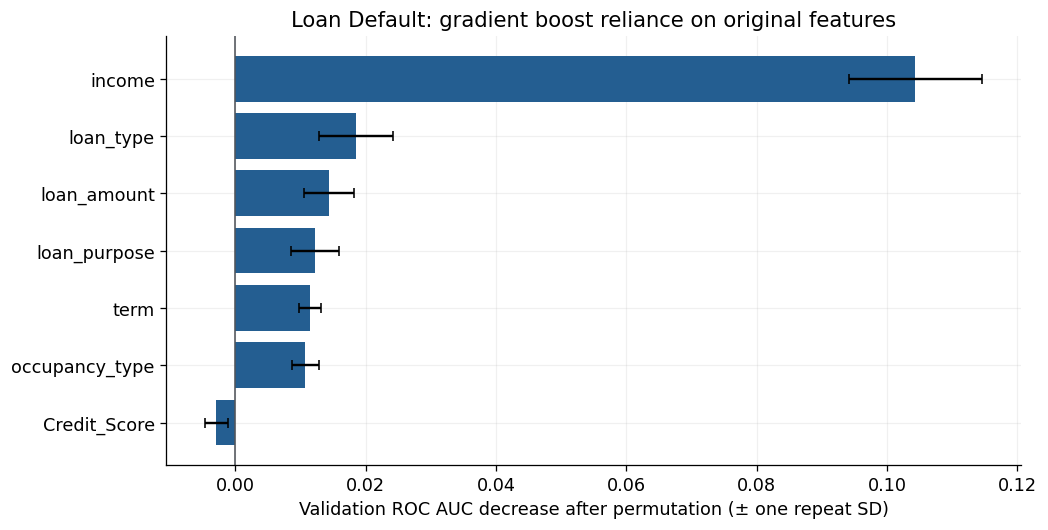

Permutation importance describes this fitted boosted ensemble on the validation partition; repeat SD is not a confidence interval. Correlated predictors can share importance. Negative values indicate that shuffling helped on this partition. With only seven bank validation records, importance is especially unstable and cannot establish population drivers.

In [9]:
# Permute original columns through the complete pipeline, not individual dummy columns.
forest=selected
importance=permutation_importance(forest,X_valid,y_valid,scoring='roc_auc',
    n_repeats=10,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'Feature':X.columns,'Mean AUC decrease':importance.importances_mean,
    'Repeat SD':importance.importances_std}).sort_values('Mean AUC decrease')
display(importance_table.sort_values('Mean AUC decrease',ascending=False))
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
ax.barh(importance_table['Feature'],importance_table['Mean AUC decrease'],
    xerr=importance_table['Repeat SD'],color=BLUE,capsize=3)
ax.axvline(0,color=GRAY,linewidth=1)
ax.set(xlabel='Validation ROC AUC decrease after permutation (± one repeat SD)',
    title=f'{plot_label}: gradient boost reliance on original features')
plt.show()
display(Markdown('Permutation importance describes this fitted boosted ensemble on the validation partition; '
    'repeat SD is not a confidence interval. Correlated predictors can share importance. '
    'Negative values indicate that shuffling helped on this partition. '
    'With only seven bank validation records, importance is especially unstable and cannot establish population drivers.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range to make score variation visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6439,0.4163,0.7742,0.5417,0.6477,0.1004,0.1738,88
Validation F1,0.6439,0.4163,0.6217,0.6101,0.3313,0.5880,0.4239,1008


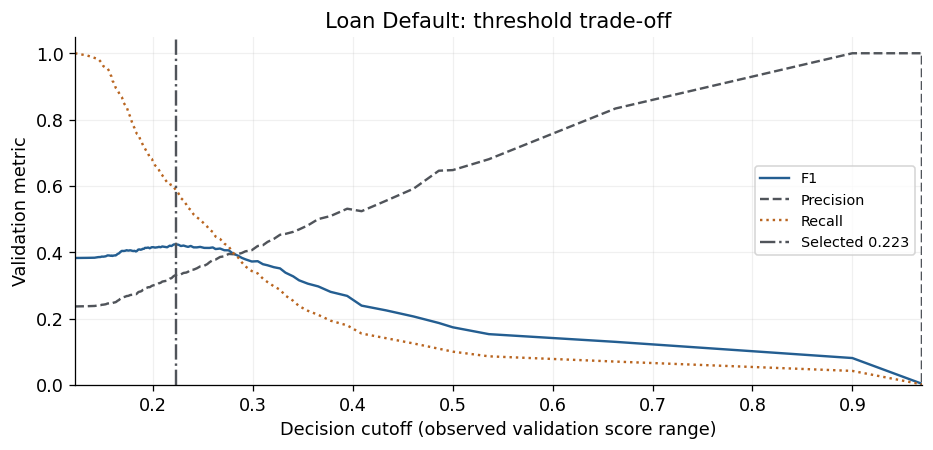

In [10]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')

if np.ptp(validation_scores)>0:
    ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

Also report log loss and Brier score (both lower is better) to separate ranking from probability quality.

In [11]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
for name, model in test_models.items():
    probability=model.predict_proba(X_test)[:,1]
    test_table.loc[name,'Log loss']=log_loss(y_test,probability,labels=[0,1])
    test_table.loc[name,'Brier score']=brier_score_loss(y_test,probability)
# A threshold changes decisions, not probability quality.
cutoff_row=chosen_name+' (validation F1 cutoff)'
test_table.loc[cutoff_row,['Log loss','Brier score']]=test_table.loc[chosen_name,['Log loss','Brier score']]

display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff, 'Logistic AUC':test_table.loc['Logistic baseline','ROC AUC'],
    'Always-positive F1':2*y_test.mean()/(1+y_test.mean())})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive,Log loss,Brier score
Model,,,,,,,,,,
Gradient boost,0.6475,0.3975,0.7712,0.5295,0.6557,0.0704,0.1272,61,0.5171,0.1689
Logistic baseline,0.5906,0.2968,0.7633,0.5000,0.0000,0.0000,0.0000,0,0.5421,0.1781
Prevalence baseline,0.5000,0.2367,0.7633,0.5000,0.0000,0.0000,0.0000,0,0.5472,0.1807
Gradient boost (validation F1 cutoff),0.6475,0.3975,0.6262,0.5991,0.3270,0.5475,0.4095,951,0.5171,0.1689


95% stratified row-bootstrap AUC interval: [0.623, 0.671]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

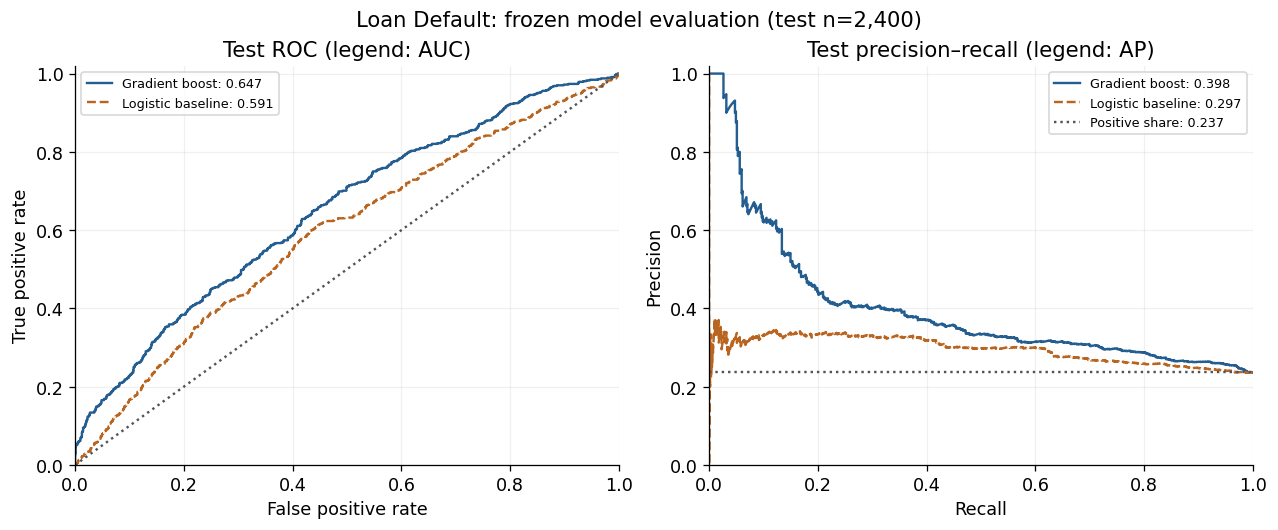

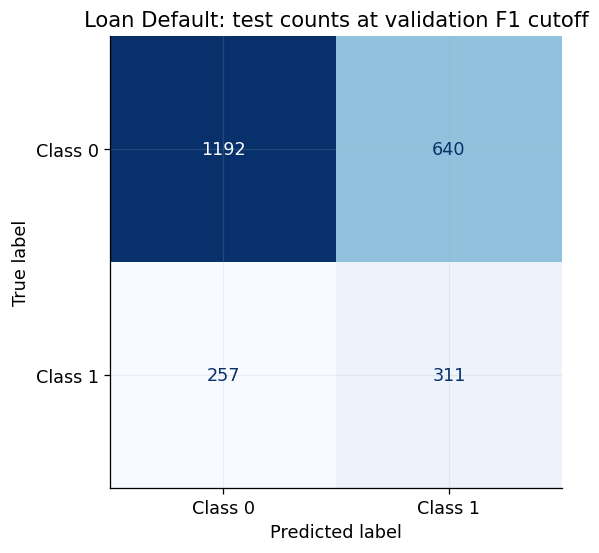

In [12]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [13]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
always_positive=2*y_test.mean()/(1+y_test.mean())
display(Markdown(f"""### Dataset takeaways — {dataset_name}

The prespecified selection gives **{chosen_name}**, with test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}** against test positive share **{r['Test positive share']:.3f}**. Logistic baseline AUC is **{log_auc:.3f}**; the descriptive AUC difference is **{r['ROC AUC']-log_auc:+.3f}**, without a significance claim.

The validation-selected cutoff yields test F1 **{r['F1 (validation cutoff)']:.3f}**, with TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. An always-positive rule on these test labels has F1 **{always_positive:.3f}**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **{test_table.loc[chosen_name,'Log loss']:.3f}** versus **{test_table.loc['Prevalence baseline','Log loss']:.3f}** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

{'Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.' if groups is not None else 'Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.'}
"""))

### Dataset takeaways — Loan_Default.csv

The prespecified selection gives **Gradient boost**, with test ROC AUC **0.647** and average precision **0.398** against test positive share **0.237**. Logistic baseline AUC is **0.591**; the descriptive AUC difference is **+0.057**, without a significance claim.

The validation-selected cutoff yields test F1 **0.409**, with TN=1192, FP=640, FN=257, TP=311. An always-positive rule on these test labels has F1 **0.383**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **0.517** versus **0.547** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.


**What this dataset teaches.** CV selected learning rate 0.03, 160 trees, depth 3, minimum leaf size 30 and subsample 0.7. In the separate full-row, leaf-10 diagnostic at rate 0.1/depth 3, increasing trees from 60 to 160 reduced training log loss from 0.494 to 0.472 while validation log loss rose from 0.511 to 0.515. More boosting can overfit. Income was the strongest validation permutation feature. Test AUC 0.647 exceeded the matched logistic baseline 0.591 descriptively; this is not a causal or significance claim.

## B. accepted_2007_to_2018Q4.csv — independent analysis

**Outcome:** Charged Off=1 versus Fully Paid=0, conditional on **resolved 2015 36-month loans**. Stream the entire 1.6 GB file and retain a uniform random-priority sample of 12,000 eligible loans. Count all source rows, cohort exclusions and unresolved/other statuses. Use application-era amount, income, FICO, DTI, revolving utilization, open accounts, home ownership, purpose and verification status. Exclude repayments, recoveries, current status, grade and pricing from predictors. No unknown or ongoing loan is labeled fully paid. Historical resolved-only selection and incomplete feature-timing documentation limit prospective interpretation.

### B1. Load and reconcile source data

In [14]:
dataset_name = 'accepted_2007_to_2018Q4.csv'
outcome_label = 'charged off among resolved 2015 36-month loans'
USECOLS = ['id', 'loan_amnt', 'annual_inc', 'fico_range_low', 'fico_range_high',
           'dti', 'revol_util', 'open_acc', 'emp_length', 'earliest_cr_line',
           'issue_d', 'loan_status', 'term', 'home_ownership', 'purpose', 'verification_status']
rng = np.random.default_rng(SEED)
frame = pd.DataFrame()
all_rows = vintage_rows = short_term_rows = eligible_rows = 0
status_counts = pd.Series(dtype='int64')
for chunk in pd.read_csv(DATA_DIR / dataset_name, usecols=USECOLS, chunksize=150_000, low_memory=False):
    all_rows += len(chunk)
    cohort = chunk.loc[chunk['issue_d'].astype('str').str.endswith('2015')].copy()
    vintage_rows += len(cohort)
    cohort = cohort.loc[cohort['term'].str.strip().eq('36 months')]
    short_term_rows += len(cohort)
    status_counts = status_counts.add(cohort['loan_status'].value_counts(), fill_value=0)
    cohort = cohort.loc[cohort['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
    eligible_rows += len(cohort)
    if len(cohort):
        cohort['_priority'] = rng.random(len(cohort))
        frame = pd.concat([frame, cohort.nsmallest(SAMPLE_SIZE, '_priority')]).nsmallest(SAMPLE_SIZE, '_priority')
frame = frame.drop(columns='_priority').reset_index(drop=True)
assert frame['id'].notna().all() and frame['id'].is_unique
display(pd.Series({'source rows': all_rows, '2015 records': vintage_rows,
    '2015 36-month records': short_term_rows, 'resolved eligible records': eligible_rows,
    'excluded unresolved/other statuses': short_term_rows - eligible_rows,
    'uniform sample': len(frame)}, name='Resolved-outcome cohort'))
display(status_counts.astype(int).rename('2015 36-month records').to_frame())
X = pd.DataFrame({
    'log_loan_amount': np.log1p(frame['loan_amnt'].where(frame['loan_amnt'] > 0)),
    'log_annual_income': np.log1p(frame['annual_inc'].where(frame['annual_inc'] >= 0)),
    'fico_mid': (frame['fico_range_low'] + frame['fico_range_high']) / 2,
    'dti': frame['dti'].where(frame['dti'] >= 0),
    'revol_util': frame['revol_util'].where(frame['revol_util'] >= 0),
    'open_acc': frame['open_acc']})
numeric = list(X.columns)
categorical = ['home_ownership', 'purpose', 'verification_status']
for name in categorical:
    X[name] = frame[name].astype(object).where(frame[name].notna(), np.nan)
y = frame['loan_status'].eq('Charged Off').astype(int)
groups = None

source rows                           2260701
2015 records                           421095
2015 36-month records                  283173
resolved eligible records              283026
excluded unresolved/other statuses        147
uniform sample                          12000
Name: Resolved-outcome cohort, dtype: int64

,2015 36-month records
loan_status,
Charged Off,42132
Current,72
Fully Paid,240894
In Grace Period,9
Late (16-30 days),5
Late (31-120 days),61


### B2. Reserve evaluation records and audit training inputs

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,6193,1007,0.1399,7200
Validation,2400,2064,336,0.1400,2400
Test,2400,2064,336,0.1400,2400


,Training missing (%)
log_loan_amount,0.0000
log_annual_income,0.0000
fico_mid,0.0000
dti,0.0000
revol_util,0.0278
open_acc,0.0000
home_ownership,0.0000
purpose,0.0000
verification_status,0.0000


,log_loan_amount,log_annual_income,fico_mid,dti,revol_util,open_acc
min,6.9088,8.6997,662.0000,0.1000,0.0000,2.0000
median,9.2104,11.0420,687.0000,17.9400,52.3000,11.0000
max,10.4631,14.4033,847.5000,39.9600,132.5000,47.0000


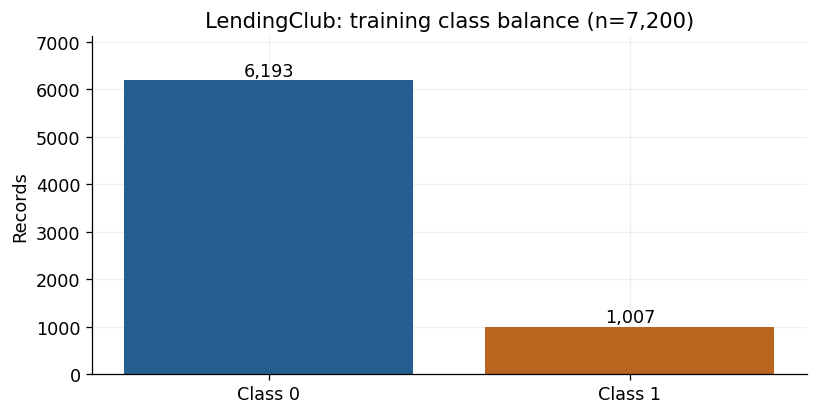

In [15]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### B3. Tune parameters inside training CV

In [16]:
# Two paired regularization profiles keep the search bounded.
# Profile effects are joint: leaf size and subsampling cannot be attributed separately here.
leaf_sizes=[1,3] if groups is not None else [10,30]
grid=[{'model__learning_rate':[0.03,0.1],'model__n_estimators':[60,160],
    'model__max_depth':[1,3],'model__min_samples_leaf':[leaf], 'model__subsample':[subsample]}
    for leaf,subsample in zip(leaf_sizes,[1.0,0.7])]
search,row=tune(GradientBoostingClassifier(loss='log_loss',random_state=SEED),grid,scale=False)
searches={'Gradient boost':search}; fitted={'Gradient boost':search.best_estimator_}
comparison=pd.DataFrame([{'Model':'Gradient boost',**row}]).set_index('Model')
chosen_name='Gradient boost'; selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Parameter':k.removeprefix('model__'),'Value':v} for k,v in search.best_params_.items()]))
display(Markdown('Three-fold training CV selects all boosting parameters. Validation is reserved for diagnostics and the F1 cutoff; '
    'the stage plots below do not change the selected model or number of trees. No automatic early stopping is used.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Gradient boost,0.6401,0.0180,0.6921,0.6439,0.2107,14.7763


,Parameter,Value
0,learning_rate,0.0300
1,max_depth,3.0000
2,min_samples_leaf,30.0000
3,n_estimators,60.0000
4,subsample,0.7000


Three-fold training CV selects all boosting parameters. Validation is reserved for diagnostics and the F1 cutoff; the stage plots below do not change the selected model or number of trees. No automatic early stopping is used.

### B4. Inspect learning rate, tree count and depth

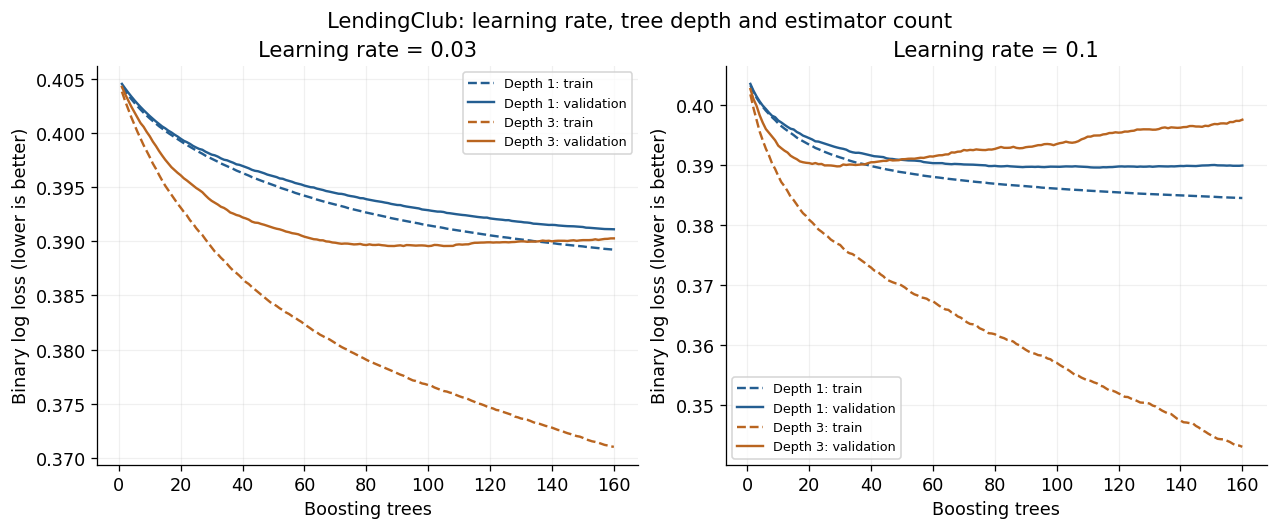

,Learning rate,Depth,Trees,Train log loss,Validation log loss
0,0.0300,1,60,0.3942,0.3951
1,0.0300,1,160,0.3892,0.3911
2,0.0300,3,60,0.3823,0.3904
3,0.0300,3,160,0.3710,0.3903
4,0.1000,1,60,0.3881,0.3904
5,0.1000,1,160,0.3846,0.3900
6,0.1000,3,60,0.3674,0.3915
7,0.1000,3,160,0.3431,0.3976


In [17]:
# Prespecified paths: training-fitted preprocessing; validation is diagnostic only.
path_prepare=prepare(numeric,categorical,scale=False)
Z_train=path_prepare.fit_transform(X_train); Z_valid=path_prepare.transform(X_valid)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
path_rows=[]
for ax,rate in zip(axes,[0.03,0.1]):
    for depth,color in [(1,BLUE),(3,ORANGE)]:
        path=GradientBoostingClassifier(learning_rate=rate,n_estimators=160,max_depth=depth,
            min_samples_leaf=leaf_sizes[0],subsample=1.0,random_state=SEED).fit(Z_train,y_train)
        train_loss=[log_loss(y_train,p,labels=[0,1]) for p in path.staged_predict_proba(Z_train)]
        valid_loss=[log_loss(y_valid,p,labels=[0,1]) for p in path.staged_predict_proba(Z_valid)]
        stages=np.arange(1,161)
        ax.plot(stages,train_loss,color=color,linestyle='--',label=f'Depth {depth}: train')
        ax.plot(stages,valid_loss,color=color,linestyle='-',label=f'Depth {depth}: validation')
        for stage in [60,160]:
            path_rows.append({'Learning rate':rate,'Depth':depth,'Trees':stage,
                'Train log loss':train_loss[stage-1],'Validation log loss':valid_loss[stage-1]})
    ax.set(title=f'Learning rate = {rate}',xlabel='Boosting trees',ylabel='Binary log loss (lower is better)')
    ax.legend(fontsize=8)
fig.suptitle(f'{plot_label}: learning rate, tree depth and estimator count')
plt.show()
display(pd.DataFrame(path_rows))

### B5. Inspect regularization in training CV

Mean training-fold AUC  \
param_model__max_depth Profile                                       
1                      70% rows; leaf ≥30                   0.6603   
                       Full rows; leaf ≥10                  0.6576   
3                      70% rows; leaf ≥30                   0.7537   
                       Full rows; leaf ≥10                  0.7591   

                                            Mean held-out-fold AUC  
param_model__max_depth Profile                                      
1                      70% rows; leaf ≥30                   0.6331  
                       Full rows; leaf ≥10                  0.6318  
3                      70% rows; leaf ≥30                   0.6324  
                       Full rows; leaf ≥10                  0.6283

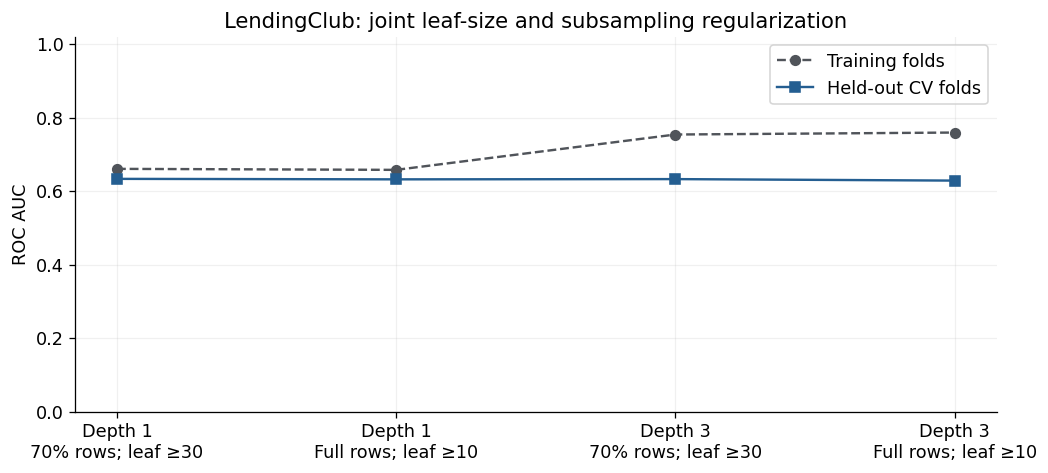

Values average equally over the four learning-rate/tree-count settings per depth/profile. Subsampling and larger leaves are changed together; this comparison does not isolate their individual effects. Shrinkage, depth limits and a finite tree count are additional regularizers.

In [18]:
cv=pd.DataFrame(search.cv_results_)
cv['Profile']=np.where(cv['param_model__subsample'].astype(float)==1.0,
    f'Full rows; leaf ≥{leaf_sizes[0]}',f'70% rows; leaf ≥{leaf_sizes[1]}')
# Average over the same rate/tree-count combinations within each depth/profile.
reg=cv.groupby(['param_model__max_depth','Profile'],sort=True)[['mean_train_auc','mean_test_auc']].mean()
display(reg.rename(columns={'mean_train_auc':'Mean training-fold AUC','mean_test_auc':'Mean held-out-fold AUC'}))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
positions=np.arange(len(reg)); labels=[f'Depth {d}\n{p}' for d,p in reg.index]
ax.plot(positions,reg['mean_train_auc'],marker='o',color=GRAY,linestyle='--',label='Training folds')
ax.plot(positions,reg['mean_test_auc'],marker='s',color=BLUE,label='Held-out CV folds')
ax.set(xticks=positions,xticklabels=labels,ylabel='ROC AUC',ylim=(0,1.02),
    title=f'{plot_label}: joint leaf-size and subsampling regularization')
ax.legend();plt.show()
display(Markdown('Values average equally over the four learning-rate/tree-count settings per depth/profile. '
    'Subsampling and larger leaves are changed together; this comparison does not isolate their individual effects. '
    'Shrinkage, depth limits and a finite tree count are additional regularizers.'))

### B6. Inspect validation permutation importance

Shuffle original input columns through the complete fitted pipeline. Importance is model reliance, not a causal effect; repeat SD is not a confidence interval.

,Feature,Mean AUC decrease,Repeat SD
2,fico_mid,0.0848,0.0141
3,dti,0.0242,0.0036
8,verification_status,0.0082,0.0045
1,log_annual_income,0.0056,0.0076
6,home_ownership,0.0042,0.0020
0,log_loan_amount,0.0039,0.0021
5,open_acc,0.0010,0.0019
4,revol_util,0.0009,0.0010
7,purpose,0.0009,0.0008


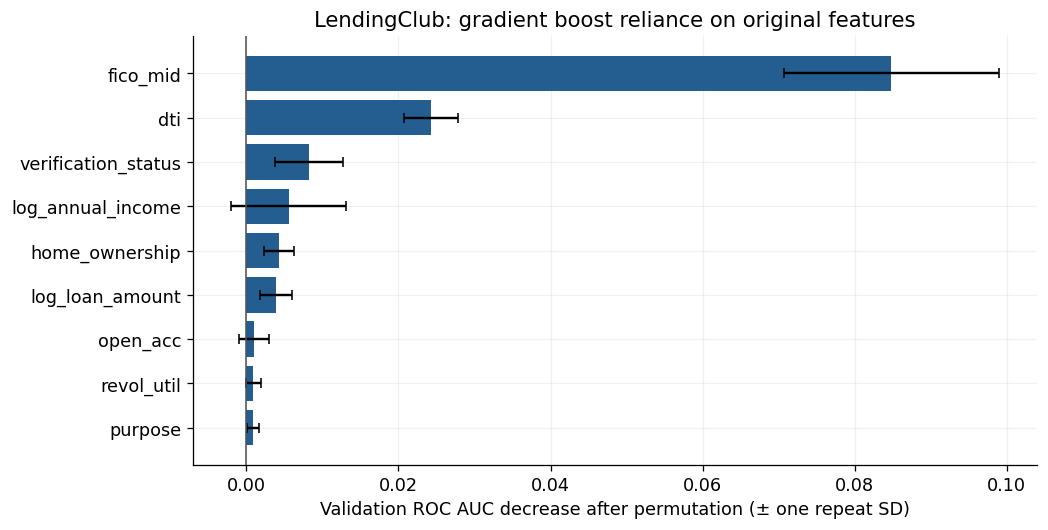

Permutation importance describes this fitted boosted ensemble on the validation partition; repeat SD is not a confidence interval. Correlated predictors can share importance. Negative values indicate that shuffling helped on this partition. With only seven bank validation records, importance is especially unstable and cannot establish population drivers.

In [19]:
# Permute original columns through the complete pipeline, not individual dummy columns.
forest=selected
importance=permutation_importance(forest,X_valid,y_valid,scoring='roc_auc',
    n_repeats=10,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'Feature':X.columns,'Mean AUC decrease':importance.importances_mean,
    'Repeat SD':importance.importances_std}).sort_values('Mean AUC decrease')
display(importance_table.sort_values('Mean AUC decrease',ascending=False))
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
ax.barh(importance_table['Feature'],importance_table['Mean AUC decrease'],
    xerr=importance_table['Repeat SD'],color=BLUE,capsize=3)
ax.axvline(0,color=GRAY,linewidth=1)
ax.set(xlabel='Validation ROC AUC decrease after permutation (± one repeat SD)',
    title=f'{plot_label}: gradient boost reliance on original features')
plt.show()
display(Markdown('Permutation importance describes this fitted boosted ensemble on the validation partition; '
    'repeat SD is not a confidence interval. Correlated predictors can share importance. '
    'Negative values indicate that shuffling helped on this partition. '
    'With only seven bank validation records, importance is especially unstable and cannot establish population drivers.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range to make score variation visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6439,0.2107,0.8600,0.5000,0.0000,0.0000,0.0000,0
Validation F1,0.6439,0.2107,0.6308,0.6072,0.2062,0.5744,0.3035,936


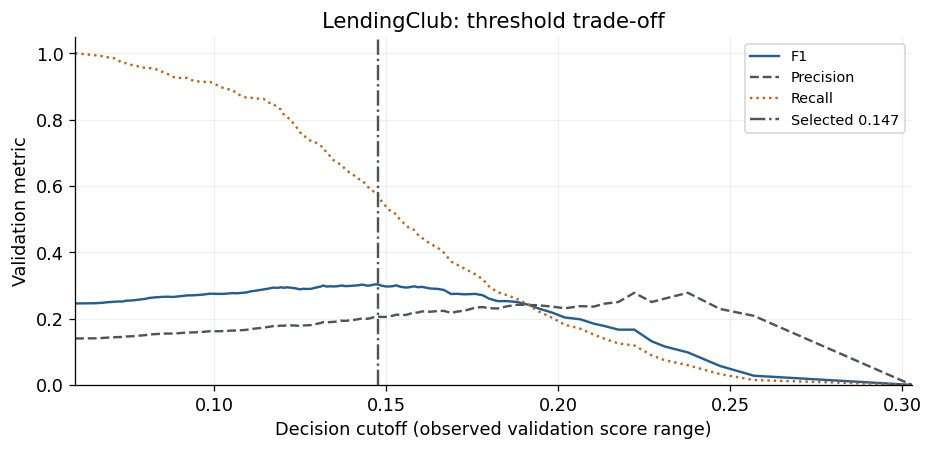

In [20]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')

if np.ptp(validation_scores)>0:
    ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

Also report log loss and Brier score (both lower is better) to separate ranking from probability quality.

In [21]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
for name, model in test_models.items():
    probability=model.predict_proba(X_test)[:,1]
    test_table.loc[name,'Log loss']=log_loss(y_test,probability,labels=[0,1])
    test_table.loc[name,'Brier score']=brier_score_loss(y_test,probability)
# A threshold changes decisions, not probability quality.
cutoff_row=chosen_name+' (validation F1 cutoff)'
test_table.loc[cutoff_row,['Log loss','Brier score']]=test_table.loc[chosen_name,['Log loss','Brier score']]

display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff, 'Logistic AUC':test_table.loc['Logistic baseline','ROC AUC'],
    'Always-positive F1':2*y_test.mean()/(1+y_test.mean())})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive,Log loss,Brier score
Model,,,,,,,,,,
Gradient boost,0.6354,0.2175,0.8600,0.5000,0.0000,0.0000,0.0000,0,0.3912,0.1171
Logistic baseline,0.6333,0.2087,0.8600,0.5000,0.0000,0.0000,0.0000,0,0.3919,0.1173
Prevalence baseline,0.5000,0.1400,0.8600,0.5000,0.0000,0.0000,0.0000,0,0.4050,0.1204
Gradient boost (validation F1 cutoff),0.6354,0.2175,0.6196,0.5820,0.1908,0.5298,0.2805,933,0.3912,0.1171


95% stratified row-bootstrap AUC interval: [0.603, 0.661]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

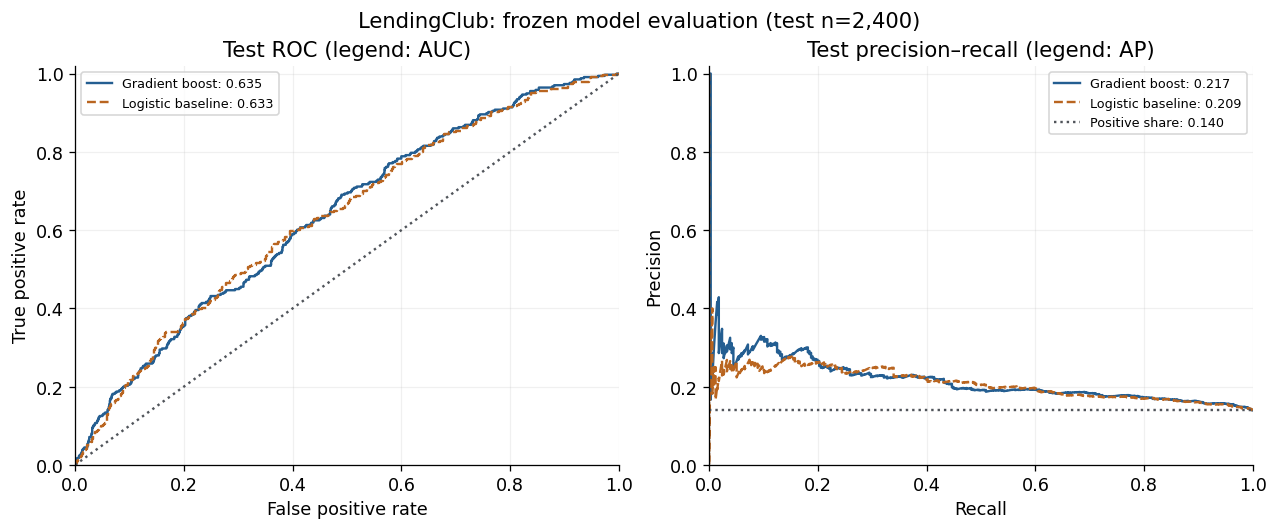

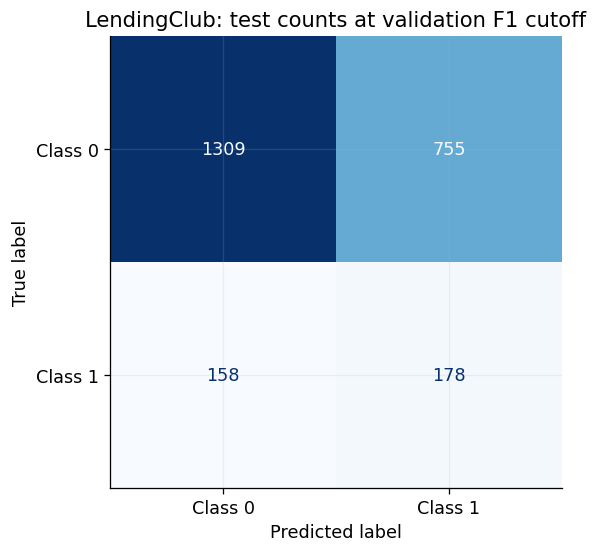

In [22]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [23]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
always_positive=2*y_test.mean()/(1+y_test.mean())
display(Markdown(f"""### Dataset takeaways — {dataset_name}

The prespecified selection gives **{chosen_name}**, with test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}** against test positive share **{r['Test positive share']:.3f}**. Logistic baseline AUC is **{log_auc:.3f}**; the descriptive AUC difference is **{r['ROC AUC']-log_auc:+.3f}**, without a significance claim.

The validation-selected cutoff yields test F1 **{r['F1 (validation cutoff)']:.3f}**, with TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. An always-positive rule on these test labels has F1 **{always_positive:.3f}**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **{test_table.loc[chosen_name,'Log loss']:.3f}** versus **{test_table.loc['Prevalence baseline','Log loss']:.3f}** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

{'Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.' if groups is not None else 'Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.'}
"""))

### Dataset takeaways — accepted_2007_to_2018Q4.csv

The prespecified selection gives **Gradient boost**, with test ROC AUC **0.635** and average precision **0.217** against test positive share **0.140**. Logistic baseline AUC is **0.633**; the descriptive AUC difference is **+0.002**, without a significance claim.

The validation-selected cutoff yields test F1 **0.281**, with TN=1309, FP=755, FN=158, TP=178. An always-positive rule on these test labels has F1 **0.246**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **0.391** versus **0.405** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.


**What this dataset teaches.** CV selected learning rate 0.03, 60 trees, depth 3, minimum leaf size 30 and subsample 0.7. The full-row, leaf-10 rate-0.1/depth-3 diagnostic reduced training loss from 0.367 to 0.343 between 60 and 160 stages, while validation loss worsened from 0.392 to 0.398. This supports inspecting shrinkage and stage count together. FICO was the strongest validation permutation feature. Test AUC 0.635 was close to logistic 0.633, so additional complexity gave little observed ranking gain.

## C. bank_customers.csv — independent analysis

**Outcome:** checking=1 versus savings/CD=0, derived from AccountType. Use only age and historical tenure as predictors; exclude AccountType itself. This file supplies **no loan-default label**, so this is an account-type classification demonstration. Keep prior date eligibility rules and group repeated AccountID values conservatively. Read no SSNs and display no personal identifiers. Explicitly report the 100-row source audit and 39-row eligible population.

### C1. Load and reconcile source data

In [24]:
dataset_name = 'bank_customers.csv'
source_frame = pd.read_csv(DATA_DIR / dataset_name, usecols=lambda name: name != 'SSN')
AS_OF = pd.Timestamp('2026-09-26')
birth_text = source_frame['BirthDate'].astype('string').str.strip()
partial_birth = birth_text.str.fullmatch(r'\d{4}', na=False)
birth = pd.to_datetime(birth_text.mask(partial_birth), format='mixed', errors='coerce')
opened = pd.to_datetime(source_frame['AccountOpened'], format='mixed', errors='coerce')
valid_type = source_frame['AccountType'].isin(['checking', 'savings', 'cd'])
eligible = (birth.notna() & opened.notna() & birth.le(AS_OF) & opened.le(AS_OF)
            & opened.ge(birth) & valid_type)
# Reason flags overlap; the union, not their sum, determines exclusions.
display(pd.Series({'source records': len(source_frame),
    'missing/invalid/partial birth date': birth.isna().sum(),
    'missing/invalid opening date': opened.isna().sum(),
    'future opening date': opened.gt(AS_OF).sum(),
    'opening before exact birth date': opened.lt(birth).sum(),
    'missing/unrecognized account type': (~valid_type).sum(),
    'eligible records': eligible.sum(), 'excluded union': (~eligible).sum()}, name='Bank eligibility audit'))
frame = source_frame.loc[eligible].copy()
frame['age_years'] = (AS_OF - birth.loc[eligible]).dt.days / 365.25
frame['tenure_years'] = (AS_OF - opened.loc[eligible]).dt.days / 365.25
# Repeated AccountID values are conservatively grouped, even though this file
# does not document whether they represent shared accounts or data-quality issues.
frame['_group'] = frame['AccountID'].astype('string')
frame['_group'] = frame['_group'].fillna(pd.Series(
    ['missing_account_' + str(i) for i in frame.index], index=frame.index))
frame = frame.reset_index(drop=True)
groups = frame['_group']
assert len(frame) >= 20
display(frame['AccountType'].value_counts().rename('eligible records').to_frame())
# BirthDate, CustomerID, AccountID, and SSN are never displayed or used as model features.

outcome_label = 'checking account versus savings/CD'
X = frame[['age_years', 'tenure_years']].copy()
y = frame['AccountType'].eq('checking').astype(int)
numeric, categorical = list(X.columns), []

source records                        100
missing/invalid/partial birth date      3
missing/invalid opening date            1
future opening date                    59
opening before exact birth date         0
missing/unrecognized account type       1
eligible records                       39
excluded union                         61
Name: Bank eligibility audit, dtype: int64

,eligible records
AccountType,
checking,16
savings,15
cd,8


### C2. Reserve evaluation records and audit training inputs

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,24,16,8,0.3333,21
Validation,7,5,2,0.2857,7
Test,8,2,6,0.7500,8


,Training missing (%)
age_years,0.0000
tenure_years,0.0000


,age_years,tenure_years
min,18.5736,1.3990
median,55.2005,23.3566
max,74.6667,64.1396


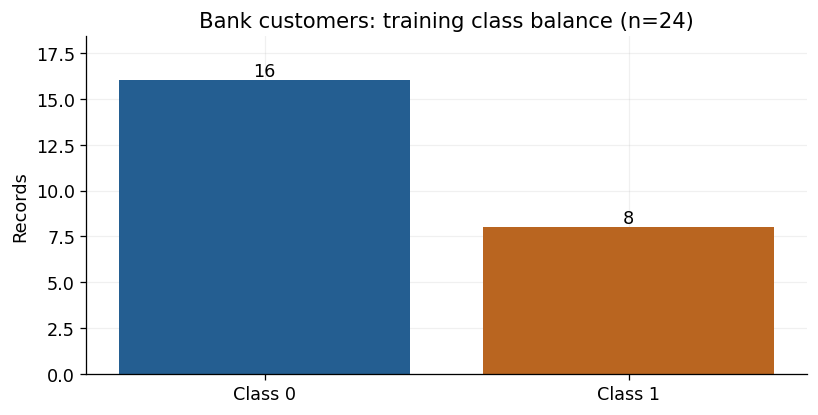

In [25]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### C3. Tune parameters inside training CV

In [26]:
# Two paired regularization profiles keep the search bounded.
# Profile effects are joint: leaf size and subsampling cannot be attributed separately here.
leaf_sizes=[1,3] if groups is not None else [10,30]
grid=[{'model__learning_rate':[0.03,0.1],'model__n_estimators':[60,160],
    'model__max_depth':[1,3],'model__min_samples_leaf':[leaf], 'model__subsample':[subsample]}
    for leaf,subsample in zip(leaf_sizes,[1.0,0.7])]
search,row=tune(GradientBoostingClassifier(loss='log_loss',random_state=SEED),grid,scale=False)
searches={'Gradient boost':search}; fitted={'Gradient boost':search.best_estimator_}
comparison=pd.DataFrame([{'Model':'Gradient boost',**row}]).set_index('Model')
chosen_name='Gradient boost'; selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Parameter':k.removeprefix('model__'),'Value':v} for k,v in search.best_params_.items()]))
display(Markdown('Three-fold training CV selects all boosting parameters. Validation is reserved for diagnostics and the F1 cutoff; '
    'the stage plots below do not change the selected model or number of trees. No automatic early stopping is used.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Gradient boost,0.6667,0.1559,1.0000,0.6000,0.4167,0.8944


,Parameter,Value
0,learning_rate,0.1000
1,max_depth,3.0000
2,min_samples_leaf,1.0000
3,n_estimators,60.0000
4,subsample,1.0000


Three-fold training CV selects all boosting parameters. Validation is reserved for diagnostics and the F1 cutoff; the stage plots below do not change the selected model or number of trees. No automatic early stopping is used.

### C4. Inspect learning rate, tree count and depth

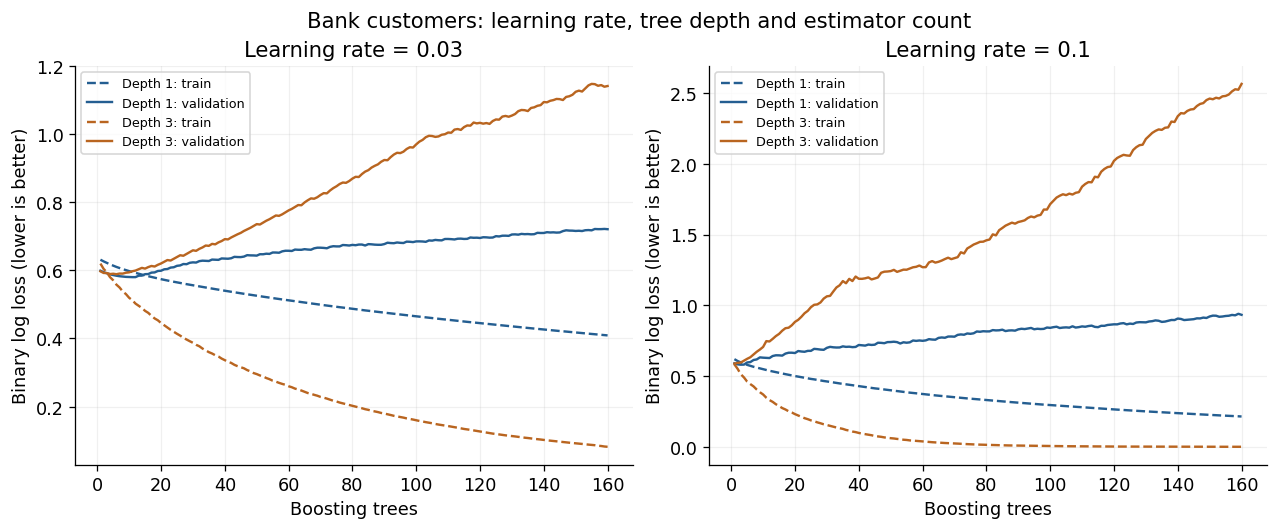

,Learning rate,Depth,Trees,Train log loss,Validation log loss
0,0.0300,1,60,0.5118,0.6574
1,0.0300,1,160,0.4090,0.7207
2,0.0300,3,60,0.2599,0.7758
3,0.0300,3,160,0.0822,1.1408
4,0.1000,1,60,0.3732,0.7489
5,0.1000,1,160,0.2143,0.9325
6,0.1000,3,60,0.0382,1.2689
7,0.1000,3,160,0.0003,2.5640


In [27]:
# Prespecified paths: training-fitted preprocessing; validation is diagnostic only.
path_prepare=prepare(numeric,categorical,scale=False)
Z_train=path_prepare.fit_transform(X_train); Z_valid=path_prepare.transform(X_valid)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
path_rows=[]
for ax,rate in zip(axes,[0.03,0.1]):
    for depth,color in [(1,BLUE),(3,ORANGE)]:
        path=GradientBoostingClassifier(learning_rate=rate,n_estimators=160,max_depth=depth,
            min_samples_leaf=leaf_sizes[0],subsample=1.0,random_state=SEED).fit(Z_train,y_train)
        train_loss=[log_loss(y_train,p,labels=[0,1]) for p in path.staged_predict_proba(Z_train)]
        valid_loss=[log_loss(y_valid,p,labels=[0,1]) for p in path.staged_predict_proba(Z_valid)]
        stages=np.arange(1,161)
        ax.plot(stages,train_loss,color=color,linestyle='--',label=f'Depth {depth}: train')
        ax.plot(stages,valid_loss,color=color,linestyle='-',label=f'Depth {depth}: validation')
        for stage in [60,160]:
            path_rows.append({'Learning rate':rate,'Depth':depth,'Trees':stage,
                'Train log loss':train_loss[stage-1],'Validation log loss':valid_loss[stage-1]})
    ax.set(title=f'Learning rate = {rate}',xlabel='Boosting trees',ylabel='Binary log loss (lower is better)')
    ax.legend(fontsize=8)
fig.suptitle(f'{plot_label}: learning rate, tree depth and estimator count')
plt.show()
display(pd.DataFrame(path_rows))

### C5. Inspect regularization in training CV

Mean training-fold AUC  \
param_model__max_depth Profile                                      
1                      70% rows; leaf ≥3                   0.9696   
                       Full rows; leaf ≥1                  0.9938   
3                      70% rows; leaf ≥3                   0.9958   
                       Full rows; leaf ≥1                  1.0000   

                                           Mean held-out-fold AUC  
param_model__max_depth Profile                                     
1                      70% rows; leaf ≥3                   0.3958  
                       Full rows; leaf ≥1                  0.4505  
3                      70% rows; leaf ≥3                   0.4167  
                       Full rows; leaf ≥1                  0.6024

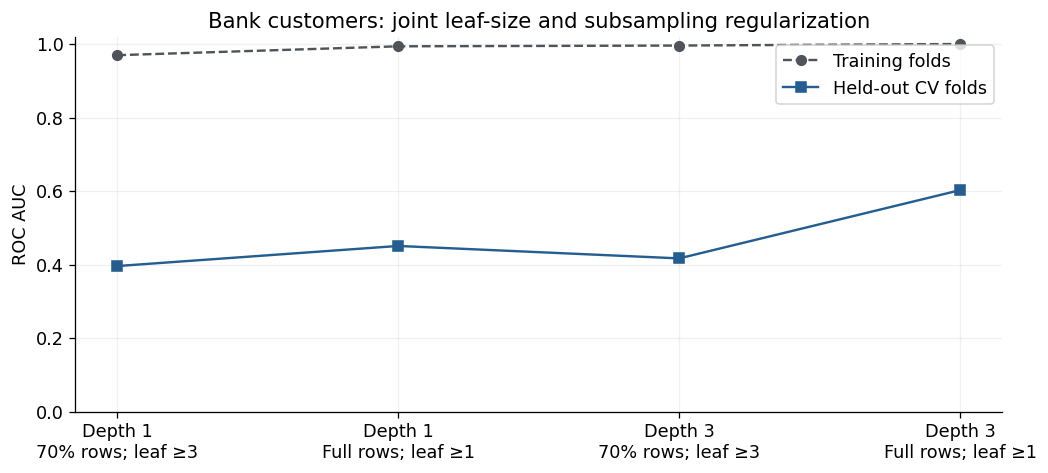

Values average equally over the four learning-rate/tree-count settings per depth/profile. Subsampling and larger leaves are changed together; this comparison does not isolate their individual effects. Shrinkage, depth limits and a finite tree count are additional regularizers.

In [28]:
cv=pd.DataFrame(search.cv_results_)
cv['Profile']=np.where(cv['param_model__subsample'].astype(float)==1.0,
    f'Full rows; leaf ≥{leaf_sizes[0]}',f'70% rows; leaf ≥{leaf_sizes[1]}')
# Average over the same rate/tree-count combinations within each depth/profile.
reg=cv.groupby(['param_model__max_depth','Profile'],sort=True)[['mean_train_auc','mean_test_auc']].mean()
display(reg.rename(columns={'mean_train_auc':'Mean training-fold AUC','mean_test_auc':'Mean held-out-fold AUC'}))
fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
positions=np.arange(len(reg)); labels=[f'Depth {d}\n{p}' for d,p in reg.index]
ax.plot(positions,reg['mean_train_auc'],marker='o',color=GRAY,linestyle='--',label='Training folds')
ax.plot(positions,reg['mean_test_auc'],marker='s',color=BLUE,label='Held-out CV folds')
ax.set(xticks=positions,xticklabels=labels,ylabel='ROC AUC',ylim=(0,1.02),
    title=f'{plot_label}: joint leaf-size and subsampling regularization')
ax.legend();plt.show()
display(Markdown('Values average equally over the four learning-rate/tree-count settings per depth/profile. '
    'Subsampling and larger leaves are changed together; this comparison does not isolate their individual effects. '
    'Shrinkage, depth limits and a finite tree count are additional regularizers.'))

### C6. Inspect validation permutation importance

Shuffle original input columns through the complete fitted pipeline. Importance is model reliance, not a causal effect; repeat SD is not a confidence interval.

,Feature,Mean AUC decrease,Repeat SD
1,tenure_years,0.2900,0.1921
0,age_years,-0.0500,0.1118


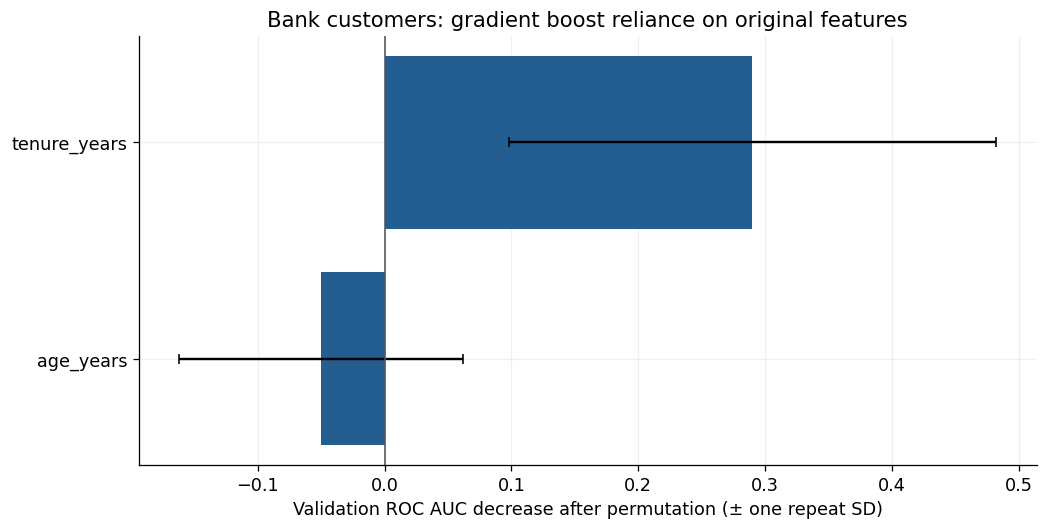

Permutation importance describes this fitted boosted ensemble on the validation partition; repeat SD is not a confidence interval. Correlated predictors can share importance. Negative values indicate that shuffling helped on this partition. With only seven bank validation records, importance is especially unstable and cannot establish population drivers.

In [29]:
# Permute original columns through the complete pipeline, not individual dummy columns.
forest=selected
importance=permutation_importance(forest,X_valid,y_valid,scoring='roc_auc',
    n_repeats=10,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'Feature':X.columns,'Mean AUC decrease':importance.importances_mean,
    'Repeat SD':importance.importances_std}).sort_values('Mean AUC decrease')
display(importance_table.sort_values('Mean AUC decrease',ascending=False))
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
ax.barh(importance_table['Feature'],importance_table['Mean AUC decrease'],
    xerr=importance_table['Repeat SD'],color=BLUE,capsize=3)
ax.axvline(0,color=GRAY,linewidth=1)
ax.set(xlabel='Validation ROC AUC decrease after permutation (± one repeat SD)',
    title=f'{plot_label}: gradient boost reliance on original features')
plt.show()
display(Markdown('Permutation importance describes this fitted boosted ensemble on the validation partition; '
    'repeat SD is not a confidence interval. Correlated predictors can share importance. '
    'Negative values indicate that shuffling helped on this partition. '
    'With only seven bank validation records, importance is especially unstable and cannot establish population drivers.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range to make score variation visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6000,0.4167,0.4286,0.6000,0.3333,1.0000,0.5000,6
Validation F1,0.6000,0.4167,0.7143,0.8000,0.5000,1.0000,0.6667,4


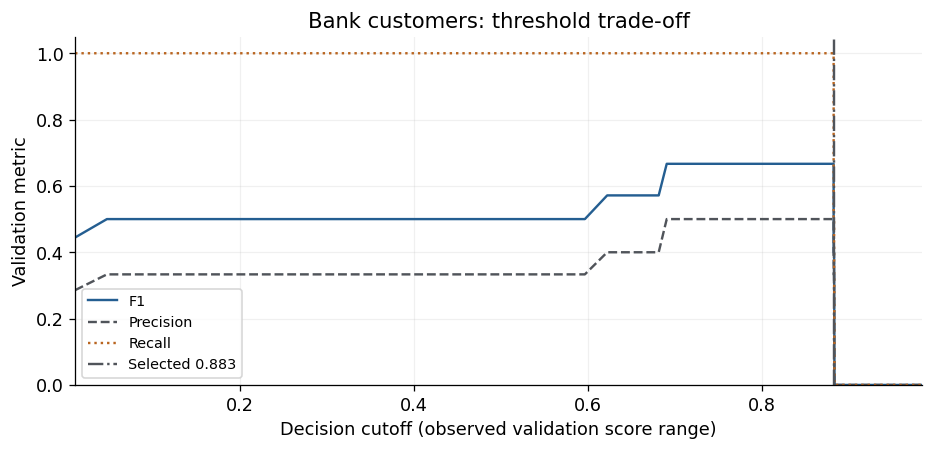

In [30]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')

if np.ptp(validation_scores)>0:
    ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

Also report log loss and Brier score (both lower is better) to separate ranking from probability quality.

In [31]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
for name, model in test_models.items():
    probability=model.predict_proba(X_test)[:,1]
    test_table.loc[name,'Log loss']=log_loss(y_test,probability,labels=[0,1])
    test_table.loc[name,'Brier score']=brier_score_loss(y_test,probability)
# A threshold changes decisions, not probability quality.
cutoff_row=chosen_name+' (validation F1 cutoff)'
test_table.loc[cutoff_row,['Log loss','Brier score']]=test_table.loc[chosen_name,['Log loss','Brier score']]

display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff, 'Logistic AUC':test_table.loc['Logistic baseline','ROC AUC'],
    'Always-positive F1':2*y_test.mean()/(1+y_test.mean())})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive,Log loss,Brier score
Model,,,,,,,,,,
Gradient boost,0.3333,0.7579,0.5000,0.5000,0.7500,0.5000,0.6000,4,2.0514,0.5213
Logistic baseline,0.5833,0.8179,0.2500,0.5000,0.0000,0.0000,0.0000,0,0.8913,0.3451
Prevalence baseline,0.5000,0.7500,0.2500,0.5000,0.0000,0.0000,0.0000,0,0.9253,0.3611
Gradient boost (validation F1 cutoff),0.3333,0.7579,0.3750,0.4167,0.6667,0.3333,0.4444,3,2.0514,0.5213


Bank test set: exact confusion counts are primary; no reliable population interval is claimed.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

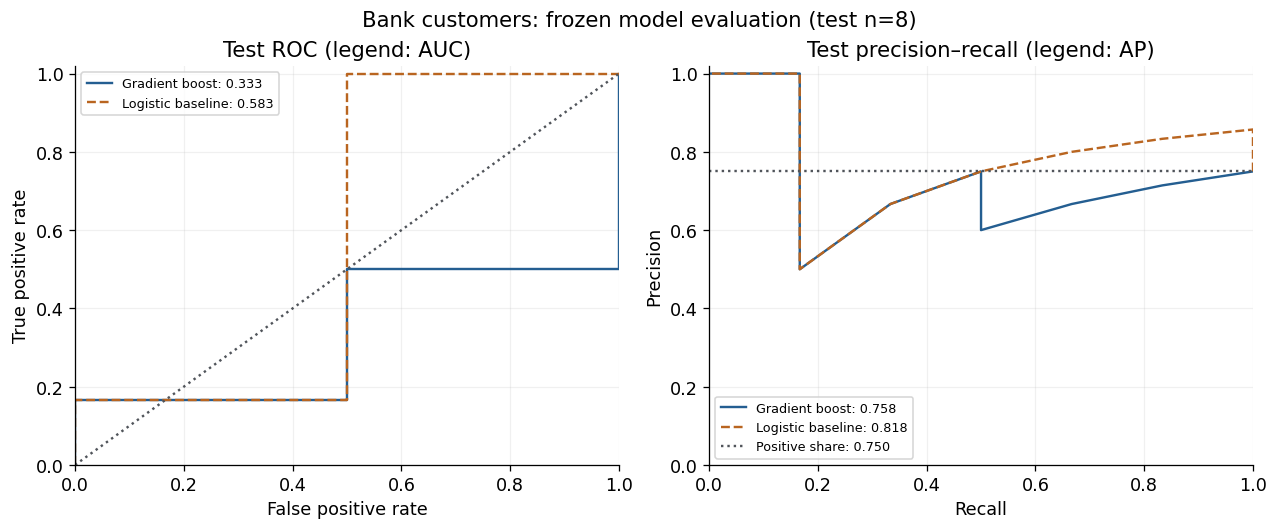

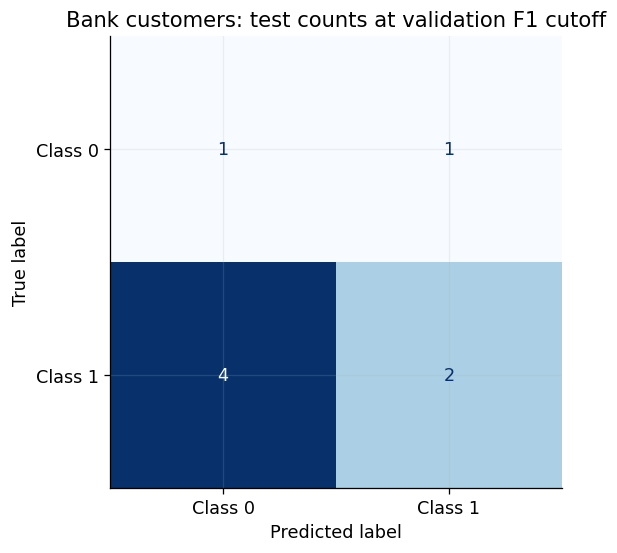

In [32]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [33]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
always_positive=2*y_test.mean()/(1+y_test.mean())
display(Markdown(f"""### Dataset takeaways — {dataset_name}

The prespecified selection gives **{chosen_name}**, with test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}** against test positive share **{r['Test positive share']:.3f}**. Logistic baseline AUC is **{log_auc:.3f}**; the descriptive AUC difference is **{r['ROC AUC']-log_auc:+.3f}**, without a significance claim.

The validation-selected cutoff yields test F1 **{r['F1 (validation cutoff)']:.3f}**, with TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. An always-positive rule on these test labels has F1 **{always_positive:.3f}**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **{test_table.loc[chosen_name,'Log loss']:.3f}** versus **{test_table.loc['Prevalence baseline','Log loss']:.3f}** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

{'Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.' if groups is not None else 'Historical random splits and conditional bootstrap intervals do not establish future-vintage performance or borrower independence.'}
"""))

### Dataset takeaways — bank_customers.csv

The prespecified selection gives **Gradient boost**, with test ROC AUC **0.333** and average precision **0.758** against test positive share **0.750**. Logistic baseline AUC is **0.583**; the descriptive AUC difference is **-0.250**, without a significance claim.

The validation-selected cutoff yields test F1 **0.444**, with TN=1, FP=1, FN=4, TP=2. An always-positive rule on these test labels has F1 **0.857**. These counts expose false-positive and false-negative tradeoffs; F1 does not encode business costs. Validation F1 is optimistic because it selected the cutoff.

Test log loss is **2.051** versus **0.925** for a training-prevalence probability. Probability quality and ranking can disagree; these scores do not establish calibration.

Only eight test records support this bank estimate. Account type is not a credit-risk outcome; no population interval is claimed.


**What this dataset teaches.** CV selected learning rate 0.1, 60 trees, depth 3, minimum leaf size 1 and full-row stages. Its training AUC was 1.000, but test AUC was 0.333. The full-row, leaf-1 rate-0.1/depth-3 path drove training loss from 0.038 at 60 trees to approximately 0.0003 at 160, while validation loss rose from 1.269 to 2.564. Test log loss 2.051 also exceeded the prevalence baseline 0.925: confident fitting did not generalize. The small grouped sample limits all conclusions.

## Takeaways across all three datasets

Compare models within a dataset; targets and populations differ. The summary below is computed from this run.

In [34]:
all_results=pd.DataFrame(results).set_index('Dataset')
assert set(all_results.index)=={'Loan_Default.csv','accepted_2007_to_2018Q4.csv','bank_customers.csv'}
assert len(all_results)==3
display(all_results)
for row in results:
    display(Markdown(f"- **{row['Dataset']}** — {row['Outcome']}: **{row['Selected']}**, test AUC **{row['ROC AUC']:.3f}**, AP **{row['Average precision']:.3f}**, F1 at the validation cutoff **{row['F1 (validation cutoff)']:.3f}**, test n={row['Test n']:,}."))

,Outcome,Selected,Train n,Validation n,Test n,ROC AUC,Average precision,Test positive share,F1 (validation cutoff),Cutoff,Logistic AUC,Always-positive F1
Dataset,,,,,,,,,,,,
Loan_Default.csv,recorded Status 1,Gradient boost,7200,2400,2400,0.6475,0.3975,0.2367,0.4095,0.2227,0.5906,0.3827
accepted_2007_to_2018Q4.csv,charged off among resolved 2015 36-month loans,Gradient boost,7200,2400,2400,0.6354,0.2175,0.1400,0.2805,0.1474,0.6333,0.2456
bank_customers.csv,checking account versus savings/CD,Gradient boost,24,7,8,0.3333,0.7579,0.7500,0.4444,0.8828,0.5833,0.8571


- **Loan_Default.csv** — recorded Status 1: **Gradient boost**, test AUC **0.647**, AP **0.398**, F1 at the validation cutoff **0.409**, test n=2,400.

- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Gradient boost**, test AUC **0.635**, AP **0.217**, F1 at the validation cutoff **0.281**, test n=2,400.

- **bank_customers.csv** — checking account versus savings/CD: **Gradient boost**, test AUC **0.333**, AP **0.758**, F1 at the validation cutoff **0.444**, test n=8.

## Milestone Two synthesis and limitations

Use the staged loss curves to connect learning rate, estimator count and depth. Training loss can keep falling while validation loss deteriorates. The joint regularization profiles illustrate constraints but do not isolate subsampling from leaf size. Validation permutation importance describes model reliance, with substantial instability on the seven-row bank validation set.

Preserve the cohort definitions, sampling audits, frozen cutoff, test counts and limitations when preparing Milestone Two. A historical random split does not establish future-cohort performance. Loan_Default needs documented status timing; LendingClub conditions on resolved outcomes; the bank study needs substantially more valid records and a decision-relevant target. Verify feature availability at prediction time and borrower identity, use future-vintage evaluation, and specify decision costs before considering operational use. No causal, fairness or deployment conclusion is supported.

The Milestone Two rubric/link was absent, so rubric-specific coverage cannot be verified.

## Sources and reproducibility

**Data:** the three original local CSVs in `DATA/`; source counts, filters, excluded outcomes, date eligibility and sample sizes are printed above. No external observations were added. The bank reference date remains 2026-09-26 solely to preserve comparisons.

**Method reference:** [scikit-learn GradientBoostingClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) (consulted October 25, 2026). The printed execution environment identifies the installed version; documentation may describe a later release.

Rerun with `python3 -m jupyter nbconvert --execute --to notebook --inplace --ExecutePreprocessor.timeout=1200 "Week 9.ipynb"` from the repository. Static summaries describe the delivered run; revise them if inputs or settings change.